# PDNO con simbolos parabolicos: laplaciano fraccionario 1D

Mismo experimento que `06_pdno_calor_1d.ipynb` en $\mathbb T^1$ con la referencia $a(k)=|k|^\alpha$ (`FractionalLaplacianSymbol`, $n=1$) para $\alpha\in\{0.5,\ 1,\ 1.5\}$, aprendiendo con orden $m=\alpha$ ($\rho=n+1=2$), con los datos de `04_fraccionario_1d.ipynb`. Hay una seccion por $\alpha$ y, al final, una tabla resumen.

Arquitectura (PDNO, Shin et al., 2024, ec. (1)), simbolo par $a_{\text{par}}$, configuracion lineal y funcion de perdida: ver `06_pdno_calor_1d.ipynb`, introduccion. Aqui la red es el semigrupo $u(t)=e^{-t\bar a(D)}u_0$ con $\bar a=a_{\text{par}}$ ($L=1$, $\tau=1$).

# Setup
El codigo de cada seccion esta en `parabolic_symbol.learning.operator_experiment.PDNOExperiment`; cada metodo es una seccion de `06_pdno_calor_1d.ipynb`.

- **Datos:** los GRF de `04` en la malla de $1024$ puntos, $k_{\text{cap}}=64$, con particion **por condicion inicial**: la validacion son $u_0$ nuevas en `TRAIN_TIMES` (early stopping); la prueba, las $20$ $u_0$ de prueba en `TEST_TIMES`.
- **$\kappa$, $(c,C)$ y $C_\alpha$:** solo con las $u_0$ de entrenamiento (`ds.rows_train`), con $m=\alpha$ y la banda sobre $\langle k\rangle^\alpha$.
- **Entrenamiento y barrido:** `TRAIN_CONFIG` (valores por defecto de `OperatorTrainingConfig` salvo `patience=60`, con `class_C_source="data"` y $k_{\max}=k_{\text{cap}}$) y el barrido `SWEEP` de la MLP del simbolo, con la arquitectura del PDNO fija. Se elige la corrida de menor $L^2$ relativa de validacion.
- **Precision:** `float32` en todo (datos, modelo, entrenamiento, evaluacion, comprobaciones y modelo guardado). Los GRF se generan con numpy y se pasan a `float32` antes de que los vea el modelo.

La celda de parametros reune todo lo configurable.

In [1]:
from pathlib import Path

import numpy as np
import torch

from parabolic_symbol.symbols.fractional_laplacian import FractionalLaplacianSymbol
from parabolic_symbol.learning.operator_experiment import PDNOExperiment, pdno_summary_figures, pdno_summary_table
from parabolic_symbol.learning.operator_training import OperatorTrainingConfig
from parabolic_symbol.utils import default_device

In [2]:
# ---------------------------------------------------------------- parametros
# Precision y device: float32 en todo (datos, modelo, entrenamiento, barrido, evaluacion,
# comprobaciones y modelo guardado).
DEVICE = default_device()
DTYPE = torch.float32

# Datos: como en 04, una referencia |k|^alpha por alpha, con m = alpha.
ALPHAS = [0.5, 1.0, 1.5]
REFERENCES = {alpha: FractionalLaplacianSymbol(n=1, alpha=alpha) for alpha in ALPHAS}   # a(k) = |k|^alpha
M = {alpha: alpha for alpha in ALPHAS}                  # orden del simbolo aprendido: m = alpha
RESOLUTION = 1024
K_CAP = 64                     # filas espectrales |k|_inf <= k_cap para (c, C) y C_alpha; k_max = k_cap
SEED = 0                       # 100 u0 de entrenamiento (TRAIN_TIMES) y 20 de prueba (TEST_TIMES)
VAL_FRACTION = 0.2             # fraccion de las u0 de entrenamiento que va a validacion
DELTA = 0.1                    # margen de la banda (c, C)
ESTIMATE_TOL = 1e-10           # filtro de senal de estimate_symbol

# Extrapolacion temporal: apagada. Ejemplo (t en [1, 2], todos > max(TRAIN_TIMES) = 0.95):
# EXTRAPOLATION_TIMES = np.linspace(1.0, 2.0, 11)
EXTRAPOLATION_TIMES = None

# Modelo: configuracion lineal del PDNO, la de 06. La MLP del simbolo y el weight decay salen del barrido.
ARCH = dict(width=1, use_W=False, bias=False, activation="identity", lift="identity", project="identity")
N_LAYERS = 1                   # L
LEARN_TAU = False              # tau fijo en 1/L
SYMBOL_HIDDEN = (64, 64, 64)   # solo para el modelo sin entrenar de las comprobaciones (seccion 3)
MODEL_SEED = 0

# Entrenamiento: valores por defecto de OperatorTrainingConfig salvo patience=60, con C_alpha de los datos.
TRAIN_CONFIG = OperatorTrainingConfig(k_max=K_CAP, class_C_source="data", patience=60)

# Barrido de la MLP del simbolo: el de 02-06 (SWEEP de learning/experiment.py), 30 corridas.
SWEEP = dict(
    depths=(2, 3, 4),
    widths=(32, 64, 128),
    dropout=0.2,
    dropout_layers=("none", "middle"),
    weight_decays=(0.0, 1e-4),
)

RESULTS = Path("../results/08_pdno_fraccionario_1d")   # tablas (CSV) y figuras (PNG); una subcarpeta por alpha y resumen.csv
RESULTS.mkdir(parents=True, exist_ok=True)
print(f"device = {DEVICE}  |  dtype = {DTYPE}")

device = cuda  |  dtype = torch.float32


In [3]:
experimentos = {
    alpha: PDNOExperiment(
        reference=REFERENCES[alpha], m=M[alpha], resolution=RESOLUTION, k_cap=K_CAP,
        results=RESULTS / f"alpha_{alpha:g}", train_config=TRAIN_CONFIG, dtype=DTYPE,
        sweep_grid=SWEEP, device=DEVICE, seed=SEED, val_fraction=VAL_FRACTION, delta=DELTA,
        estimate_tol=ESTIMATE_TOL, extrapolation_times=EXTRAPOLATION_TIMES, arch=ARCH,
        n_layers=N_LAYERS, learn_tau=LEARN_TAU, symbol_hidden=SYMBOL_HIDDEN, model_seed=MODEL_SEED,
    )
    for alpha in ALPHAS
}

# $\alpha = 0.5$

$a(k)=|k|^{0.5}$, $m=0.5$, malla $1024$ puntos, $k_{\text{cap}}=64$. Tablas y figuras en `results/08_pdno_fraccionario_1d/alpha_0.5/`.

In [4]:
exp_0_5 = experimentos[0.5]

## 1. Datos

`field_datasets` genera los mismos GRF que 02 / 04 y los devuelve como campos $u_0$ de forma `(n_ic, 1024)` y $u$ de forma `(n_ic, T, 1024)`, con todos los modos de la malla, en `DTYPE`. Particion por condicion inicial y comprobaciones de disjuncion: ver `06_pdno_calor_1d.ipynb`, seccion 1.

In [5]:
display(exp_0_5.load_data())

ENTRENAMIENTO
100 condiciones iniciales x 10 tiempos, resolucion 1024: 1290 pares (k, t) con |k|_inf <= 64 -> 129,000 muestras
  ventana de k: 129 k, |k|_inf <= 64, |k| in [0, 64]
PRUEBA
20 condiciones iniciales x 20 tiempos, resolucion 1024: 2580 pares (k, t) con |k|_inf <= 64 -> 51,600 muestras
  ventana de k: 129 k, |k|_inf <= 64, |k| in [0, 64]
CAMPOS (condicion inicial x tiempo)
  train        : 80 u0 x 10 tiempos = 800 pares, malla (1024,)
  val          : 20 u0 x 10 tiempos = 200 pares, malla (1024,)
  test         : 20 u0 x 20 tiempos = 400 pares, malla (1024,)

k_max = k_cap = 64
entrenamiento :  80 condiciones iniciales x 10 tiempos =  800 pares
validacion    :  20 condiciones iniciales x 10 tiempos =  200 pares
prueba        :  20 condiciones iniciales x 20 tiempos =  400 pares
entrenamiento y validacion disjuntos: True
prueba: min ||u0_prueba - u0_vista|| / ||u0_prueba|| = 1.007  (> 0: disjunta)
filas espectrales para la banda y las C_alpha: 103,200 (solo las 80 u0 de entre

,condiciones_iniciales,tiempos,pares,t_min,t_max
conjunto,,,,,
entrenamiento,80,10,800,0.05,0.95
validacion,20,10,200,0.05,0.95
prueba,20,20,400,0.05,1.00


**Condiciones iniciales y evolucion.** Dos $u_0$ de entrenamiento y la solucion exacta en algunos tiempos de `TRAIN_TIMES`, una imagen por $u_0$.

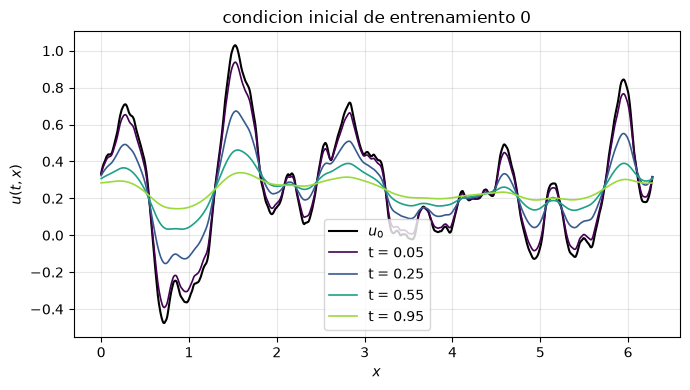

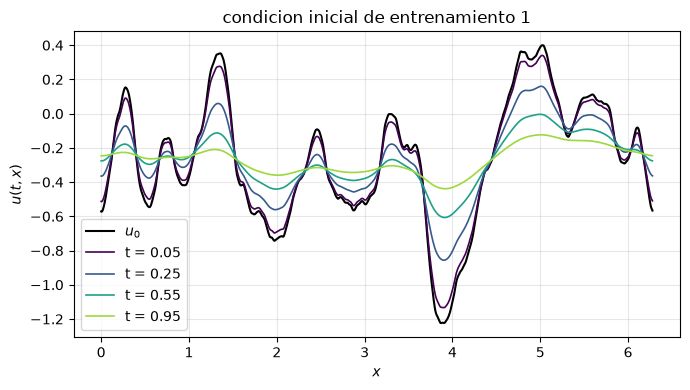

In [6]:
exp_0_5.initial_conditions()

## 2. Banda $(c,C)$, $\kappa$ y constantes $C_\alpha$

Como en 06, sobre `ds.rows_train` (las filas espectrales de las $u_0$ de entrenamiento): $\hat a(k)$, $(c,C)$ con $\delta=0.1$, $\kappa=$ `theoretical_kappa()` y las $C_\alpha$ con margen $1.5$ para todos los $\alpha$ con $|\alpha|\le\rho=n+1=2$. Las del oraculo son solo comparacion.

In [7]:
display(exp_0_5.estimate_constants())

estimate_symbol: 103,200 de 103,200 pares (k, t) con senal (tol=1e-10); 129 de 129 k de entrenamiento
  ventana usada: 129 k, |k|_inf <= 64, |k| in [0, 64]
(c, C) de los datos = (0.7568, 1.0999)   m = 0.5, ventana: 128 k, |k|_inf <= 64, |k| in [1, 64]
kappa teorico       = 2.0000   (omega = 1)
C_alpha estimadas   = 3 multiindices, |alpha| <= rho = 2


,C_alpha datos (x1.5),C_alpha oraculo (x1.5),k_usados
alpha,,,
"(0,)",1.499908,1.499908,129
"(1,)",1.783811,1.783811,128
"(2,)",5.045379,5.045378,127


## 3. Comprobaciones antes de entrenar

Con un modelo recien construido (pesos aleatorios, MLP `SYMBOL_HIDDEN`, modo eval), como en 06:

- **Paridad:** $\max_k|a_{\text{par}}(k)-a_{\text{par}}(-k)|$ en $|k|\le512$ (Nyquist). Debe ser $0$.
- **Reduccion:** el PDNO frente a $e^{-t\bar a(k)}\hat u_0(k)$ en el layout de los datos (`np.fft`) y, ademas, con la FFT completa (`fftn`, todos los modos, sin medio espacio). Error maximo relativo $\max_x|u_\theta-u|/\max_x|u|$.
- **Semigrupo:** $\max\|S(t+s)u_0-S(t)S(s)u_0\|/\|u_0\|$ para varios pares $(t,s)$.

Todo en `DTYPE`: reduccion y semigrupo deben quedar en unas pocas unidades del redondeo de float32 ($\sim10^{-6}$).

In [8]:
display(exp_0_5.checks())

tau = [1.]
capa 0: max |a(k) - a(-k)| = 0.000e+00   (|k| <= 512)


,valor,esperado
comprobacion,,
"paridad: max |a(k) - a(-k)|, |k| <= 512",0.000000e+00,0
"reduccion: max error relativo (4 u0 de prueba, t = [0.05, 0.5, 1.0])",2.929411e-07,~1e-06
"reduccion (fftn completa): max error relativo (4 u0 de prueba, t = [0.05, 0.5, 1.0])",2.323176e-07,~1e-06
semigrupo: max ||S(t+s)u0 - S(t)S(s)u0|| / ||u0|| (5 pares),2.449132e-07,~1e-06


## 4. Barrido de la MLP del simbolo

El barrido de la celda de parametros (`SWEEP`, el de 02-06): $\{2,3,4\}$ capas ocultas $\times$ $\{32,64,128\}$ neuronas, dropout $0.2$ en `none` o `middle` y weight decay $\{0,10^{-4}\}$, $30$ corridas con la arquitectura del PDNO fija y `TRAIN_CONFIG`. Cada una es `train_operator` con `rows=ds.rows_train` (`class_C_source="data"`) y early stopping con paciencia $60$ sobre la perdida total de validacion. Detalles: ver `06_pdno_calor_1d.ipynb`, seccion 4.

In [9]:
exp_0_5.sweep()

[  1/30] 2x32  drop[-] wd=0e+00 | rel_l2=0.0003 |  71.3s
[  2/30] 2x32  drop[-] wd=1e-04 | rel_l2=0.0003 |  69.2s
[  3/30] 2x64  drop[-] wd=0e+00 | rel_l2=0.0003 |  69.3s
[  4/30] 2x64  drop[-] wd=1e-04 | rel_l2=0.0003 |  68.5s
[  5/30] 2x128 drop[-] wd=0e+00 | rel_l2=0.0003 |  69.9s
[  6/30] 2x128 drop[-] wd=1e-04 | rel_l2=0.0003 |  70.3s
[  7/30] 3x32  drop[-] wd=0e+00 | rel_l2=0.0003 |  18.2s
[  8/30] 3x32  drop[-] wd=1e-04 | rel_l2=0.0003 |  72.3s
[  9/30] 3x32  drop[1] wd=0e+00 | rel_l2=0.0009 |  57.0s
[ 10/30] 3x32  drop[1] wd=1e-04 | rel_l2=0.0009 |  47.1s
[ 11/30] 3x64  drop[-] wd=0e+00 | rel_l2=0.0003 |  72.9s
[ 12/30] 3x64  drop[-] wd=1e-04 | rel_l2=0.0003 |  72.8s
[ 13/30] 3x64  drop[1] wd=0e+00 | rel_l2=0.0007 |  63.6s
[ 14/30] 3x64  drop[1] wd=1e-04 | rel_l2=0.0008 |  75.6s
[ 15/30] 3x128 drop[-] wd=0e+00 | rel_l2=0.0003 |  75.1s
[ 16/30] 3x128 drop[-] wd=1e-04 | rel_l2=0.0003 |  75.7s
[ 17/30] 3x128 drop[1] wd=0e+00 | rel_l2=0.0009 |  79.1s
[ 18/30] 3x128 drop[1] wd=1e-04

In [10]:
barrido, por_eje = exp_0_5.sweep_results()
display(barrido)
for tabla in por_eje:
    display(tabla)

,capas,ancho,dropout,weight_decay,val_rel_l2,val_total,val_par_max_ratio
0,4,128,OFF,0.0000,0.000015,0.000015,0.594525
1,4,128,OFF,0.0001,0.000021,0.000021,0.594512
2,3,128,OFF,0.0000,0.000255,0.000255,0.594508
3,3,128,OFF,0.0001,0.000265,0.000265,0.594503
4,3,32,OFF,0.0001,0.000292,0.000292,0.594504
5,3,32,OFF,0.0000,0.000296,0.000296,0.594492
6,2,32,OFF,0.0000,0.000299,0.000299,0.594503
7,2,32,OFF,0.0001,0.000299,0.000299,0.594503
8,3,64,OFF,0.0000,0.000301,0.000301,0.594504
9,3,64,OFF,0.0001,0.000301,0.000301,0.594504


,corridas,mejor_val_rel_l2,mejor_val_total,peor_ratio
dropout,,,,
OFF,18,0.000015,0.000015,0.594492
"ON p=0.2 capas[1,2]",6,0.001182,0.001182,0.593430
ON p=0.2 capas[1],6,0.000745,0.000745,0.593186


,corridas,mejor_val_rel_l2,mejor_val_total,peor_ratio
weight_decay,,,,
0.0000,15,0.000015,0.000015,0.593430
0.0001,15,0.000021,0.000021,0.593186


### Seleccion: la mejor aproximacion

La corrida de **menor $L^2$ relativa de validacion** (`best_run`). Desde aqui, las secciones 5 a 10 usan la corrida elegida.

In [11]:
display(exp_0_5.select())

kappa = theoretical_kappa() = 2.0000
arquitectura elegida    = 4 capas x 128 neuronas (MLP del simbolo)
dropout                 = OFF
weight decay            = 0  (Linear ocultas interiores)
early stopping          = mejor epoca 299 de 300 epocas; se detuvo antes del final: False
tau                     = [1.]
C_alpha de train_operator = las de class_C.csv: True

metricas de validacion en la mejor epoca:
  total             = 1.5355e-05
  rel_l2            = 0.0000
  parabolicidad     = 0.0000e+00   (0 => ningun punto viola la cota)
  clase             = 0.0000e+00
  peor ratio        = 0.5945
  puntos con >1     = 0.00%


total                   0.000015
rel_l2                  0.000015
parabolicidad           0.000000
clase                   0.000000
peor ratio              0.594525
puntos con ratio > 1    0.000000
Name: validacion (mejor epoca), dtype: float64

## 5. Curvas de entrenamiento

Perdida total y cada termino por epoca, en entrenamiento y validacion, cada uno en su imagen (`perdida_total.png`, `perdida_rel_l2.png`, `perdida_parabolicidad.png`, `perdida_clase.png`); la linea punteada marca la epoca restaurada por el early stopping. Las perdidas por epoca se guardan en `historia.csv`, que leen los benchmarks contra el FNO.

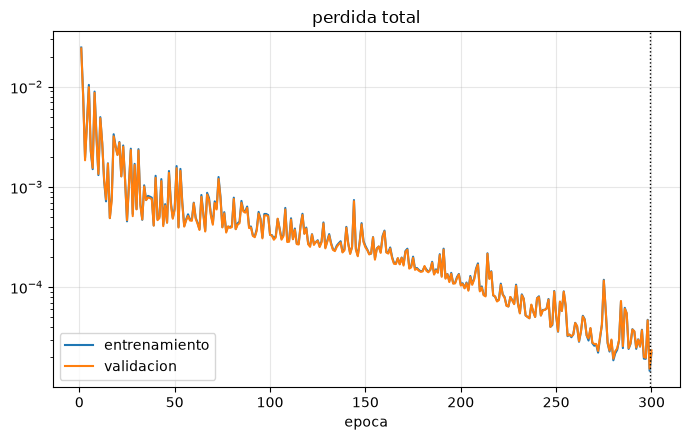

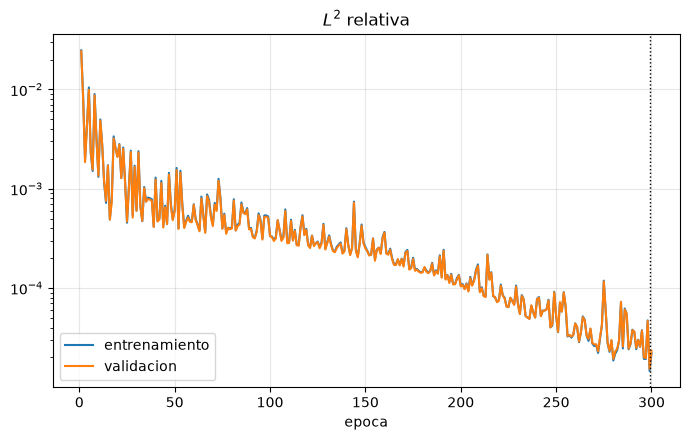

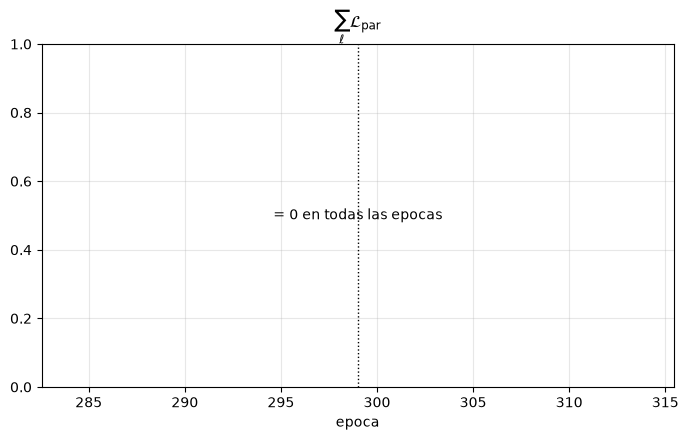

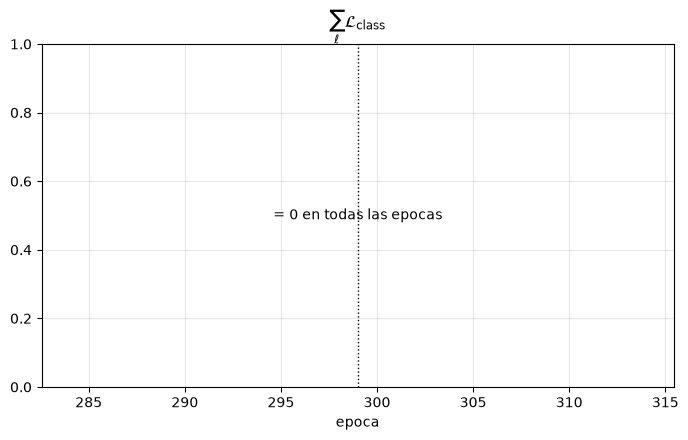

In [12]:
exp_0_5.curves()

## 6. Prueba

`field_errors` sobre las $20$ $u_0$ de prueba en `TEST_TIMES`: error relativo $L^2$ en espacio fisico por condicion inicial y tiempo. Se imprime tambien la $L^2$ relativa sobre los pares $(k,t)$ de prueba con $|k|\le k_{\max}$, con el simbolo efectivo: la `test_rel_l2` de 04 y del resumen.

PRUEBA -- 20 condiciones iniciales nuevas x 20 tiempos
error relativo L2 (espacio fisico) = 1.3508e-05  (medio; max 2.7152e-05)
error relativo L2 (pares (k, t), |k| <= 64, simbolo efectivo) = 1.1535e-05


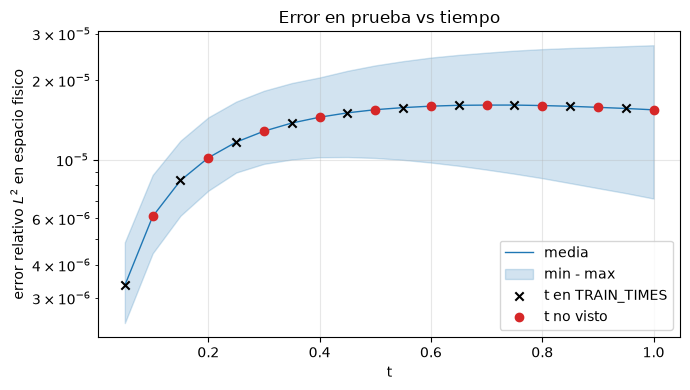

,media,max,en_entrenamiento
t,,,
0.05,0.000003,0.000005,True
0.10,0.000006,0.000009,False
0.15,0.000008,0.000012,True
0.20,0.000010,0.000014,False
0.25,0.000012,0.000017,True
0.30,0.000013,0.000018,False
0.35,0.000014,0.000020,True
0.40,0.000014,0.000020,False
0.45,0.000015,0.000022,True


In [13]:
display(exp_0_5.test())

**Campo.** Primera condicion inicial de prueba en algunos tiempos de `TEST_TIMES`: exacta (continua) y PDNO (punteada) en `campo.png`, y el error puntual en `campo_error.png`.

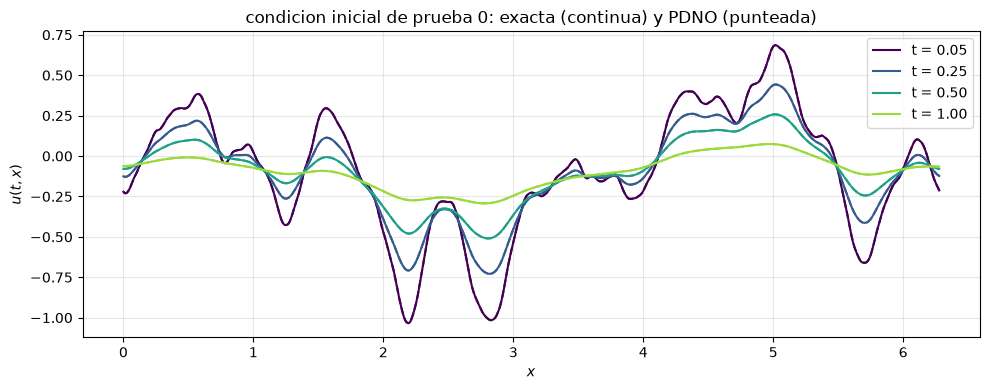

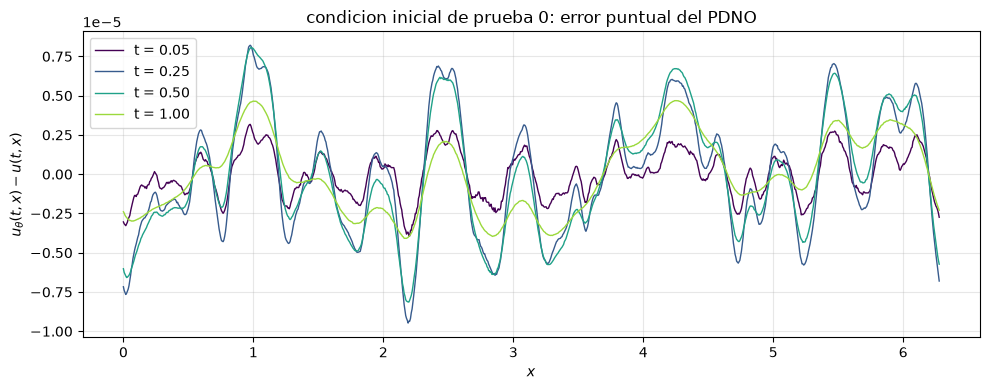

In [14]:
exp_0_5.field_figure()

## 7. Simbolo aprendido

El simbolo efectivo $\bar a(k)$ frente a $|k|^{0.5}$ en todos los modos de la malla, $|k|\le512$, contra $|k|$; la zona sombreada es la ventana $|k|\le k_{\max}=64$. En `simbolo_banda.png`, $\bar a(k)/\langle k\rangle^m$, que esta siempre en la banda $(c,C)$ por construccion.

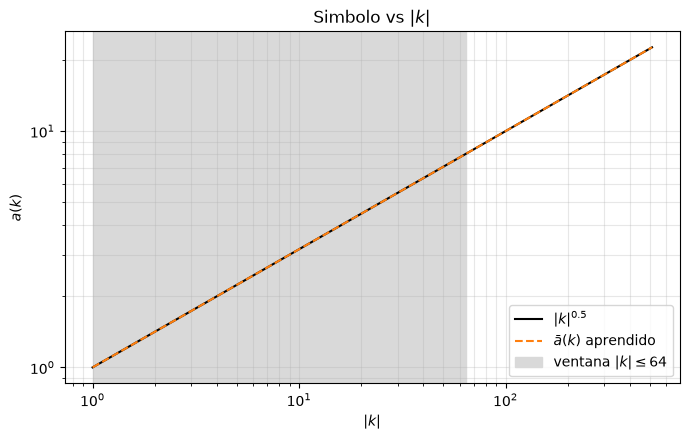

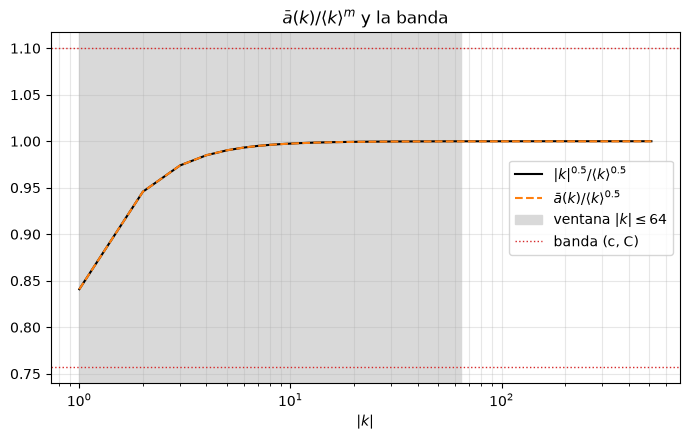

In [15]:
exp_0_5.symbol_figure()

**Error del simbolo.** $|\bar a(k)-a(k)|/a(k)$ en cada $k$ ($k=0$ se omite), dentro y fuera de la ventana.

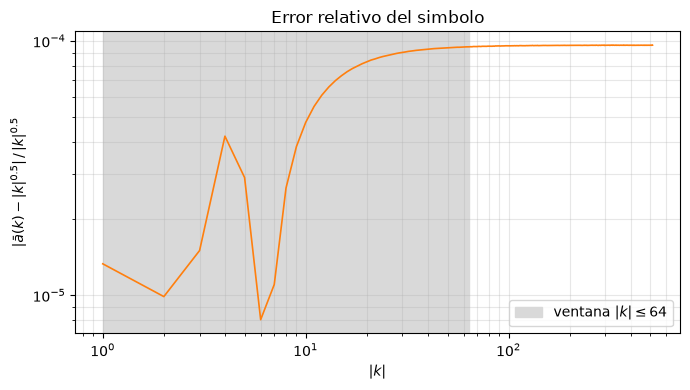

,dentro (|k| <= 64),fuera (|k| > 64)
n,1.290000e+02,896.000000
mse,2.639758e-07,0.000003
rmse,5.137858e-04,0.001632
mae,4.598432e-04,0.001584
max_error,7.581711e-04,0.002177
rel_l2,9.047535e-05,0.000096
error_relativo_medio,7.832723e-05,0.000096
error_relativo_max,9.477139e-05,0.000096


In [16]:
display(exp_0_5.symbol_error())

**Multiplicador.** $e^{-t\bar a(k)}$ aprendido (punteado) frente a $e^{-t|k|^{0.5}}$ (continuo) sobre $0\le k\le k_{\max}$; su diferencia absoluta va en `multiplicador_error.png`.

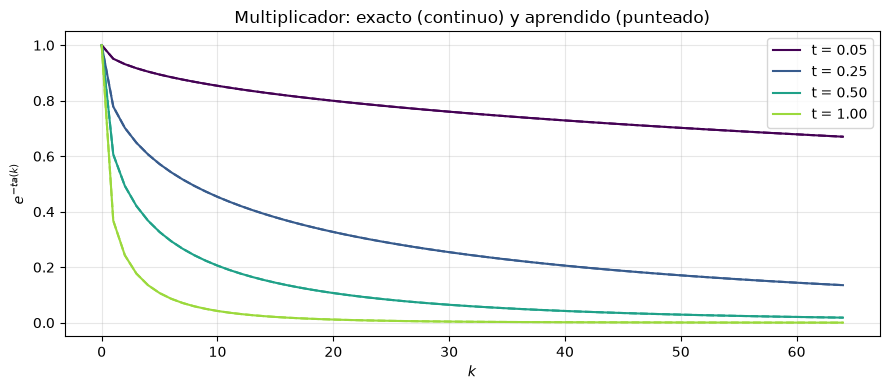

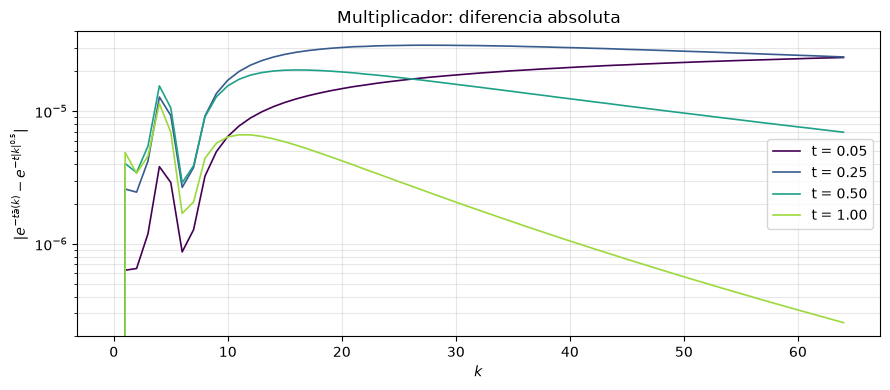

In [17]:
exp_0_5.multiplier()

## 8. Certificacion

**Parabolicidad (Def. 2.3).** `ParabolicityVerifier` sobre el simbolo de cada capa y el efectivo, con la rejilla de `GRFExperiment`: $|k_i|\le K$, $K\in\{k_{\max},2k_{\max},3k_{\max}\}$, y `CERT_LAM`. Se cumple si el peor ratio $\hat\kappa/\kappa$ es $\le1$.

**Clase $S^{m,\rho}$ (Def. 2.1).** `SymbolClassVerifier` en ventanas crecientes; es evidencia en una ventana finita, no una prueba sobre todo $\mathbb Z^n$.

In [18]:
display(exp_0_5.certification())

kappa usada = 2.0000


,simbolo,K,region,puntos,max_ratio,satisfecha
0,capa 0,64,dentro,80625,0.594582,True
1,capa 0,128,fuera,160625,0.594582,True
2,capa 0,192,fuera,240625,0.594582,True
3,efectivo,64,dentro,80625,0.594582,True
4,efectivo,128,fuera,160625,0.594582,True
5,efectivo,192,fuera,240625,0.594582,True


In [19]:
display(exp_0_5.symbol_class())

capa 0: consistentes 3 de 3 multiindices
efectivo: consistentes 3 de 3 multiindices
ventana explorada: |k| <= 128 (evidencia, no prueba sobre todo Z^n)
pendiente = nan significa Delta^alpha a = 0 en la ventana, asi que C_alpha = 0 basta


,simbolo,alpha,|alpha|,C_hat(4),C_hat(8),C_hat(12),C_hat(128),crecim.(12->128),pendiente,m-|alpha|,estable,consistente
0,capa 0,"(0,)",0,0.985000,0.996105,0.998210,0.999889,1.001682,0.500061,0.5,True,True
1,capa 0,"(1,)",1,1.189191,1.189191,1.189191,1.189191,1.000000,-0.502839,-0.5,True,True
2,capa 0,"(2,)",2,3.363541,3.363541,3.363541,3.363541,1.000000,-1.516895,-1.5,True,True
3,efectivo,"(0,)",0,0.985000,0.996105,0.998210,0.999889,1.001682,0.500061,0.5,True,True
4,efectivo,"(1,)",1,1.189191,1.189191,1.189191,1.189191,1.000000,-0.502839,-0.5,True,True
5,efectivo,"(2,)",2,3.363541,3.363541,3.363541,3.363541,1.000000,-1.516895,-1.5,True,True


## 9. Extrapolacion temporal

Solo si `EXTRAPOLATION_TIMES` no es `None`: las $u_0$ de prueba en tiempos $t>0.95$. Solo se reporta.

In [20]:
tabla_ext = exp_0_5.extrapolation()
if tabla_ext is not None:
    display(tabla_ext)

EXTRAPOLATION_TIMES = None: seccion omitida


## 10. Modelo guardado

`save_operator_model` guarda en `results/08_pdno_fraccionario_1d/alpha_0.5/modelo.pt` la corrida seleccionada (pesos, `PDNOConfig`, `OperatorTrainingConfig`, $C_\alpha$, dtype y lo necesario para regenerar los datos). Para reconstruirlo sin este notebook:

```python
from parabolic_symbol.learning.operator_training import load_operator_datasets, load_operator_model
model = load_operator_model("results/08_pdno_fraccionario_1d/alpha_0.5/modelo.pt")
ds = load_operator_datasets("results/08_pdno_fraccionario_1d/alpha_0.5/modelo.pt", dtype=model.dtype)   # misma semilla, mismos datos
```

La ultima celda recarga el modelo y comprueba que da el mismo error de prueba.

In [21]:
exp_0_5.save_model()

modelo guardado en ../results/08_pdno_fraccionario_1d/alpha_0.5/modelo.pt


PosixPath('../results/08_pdno_fraccionario_1d/alpha_0.5/modelo.pt')

In [22]:
exp_0_5.check_saved_model()

dtype del modelo cargado = torch.float32
error de prueba (cargado) = 1.350840e-05  |  (entrenado) = 1.350840e-05
identicos: True


True

# $\alpha = 1$

$a(k)=|k|^{1}$, $m=1$, malla $1024$ puntos, $k_{\text{cap}}=64$. Tablas y figuras en `results/08_pdno_fraccionario_1d/alpha_1/`.

In [23]:
exp_1_0 = experimentos[1.0]

## 1. Datos

In [24]:
display(exp_1_0.load_data())

ENTRENAMIENTO
100 condiciones iniciales x 10 tiempos, resolucion 1024: 1290 pares (k, t) con |k|_inf <= 64 -> 129,000 muestras
  ventana de k: 129 k, |k|_inf <= 64, |k| in [0, 64]
PRUEBA
20 condiciones iniciales x 20 tiempos, resolucion 1024: 2580 pares (k, t) con |k|_inf <= 64 -> 51,600 muestras
  ventana de k: 129 k, |k|_inf <= 64, |k| in [0, 64]
CAMPOS (condicion inicial x tiempo)
  train        : 80 u0 x 10 tiempos = 800 pares, malla (1024,)
  val          : 20 u0 x 10 tiempos = 200 pares, malla (1024,)
  test         : 20 u0 x 20 tiempos = 400 pares, malla (1024,)

k_max = k_cap = 64
entrenamiento :  80 condiciones iniciales x 10 tiempos =  800 pares
validacion    :  20 condiciones iniciales x 10 tiempos =  200 pares
prueba        :  20 condiciones iniciales x 20 tiempos =  400 pares
entrenamiento y validacion disjuntos: True
prueba: min ||u0_prueba - u0_vista|| / ||u0_prueba|| = 1.007  (> 0: disjunta)
filas espectrales para la banda y las C_alpha: 103,200 (solo las 80 u0 de entre

,condiciones_iniciales,tiempos,pares,t_min,t_max
conjunto,,,,,
entrenamiento,80,10,800,0.05,0.95
validacion,20,10,200,0.05,0.95
prueba,20,20,400,0.05,1.00


**Condiciones iniciales y evolucion.**

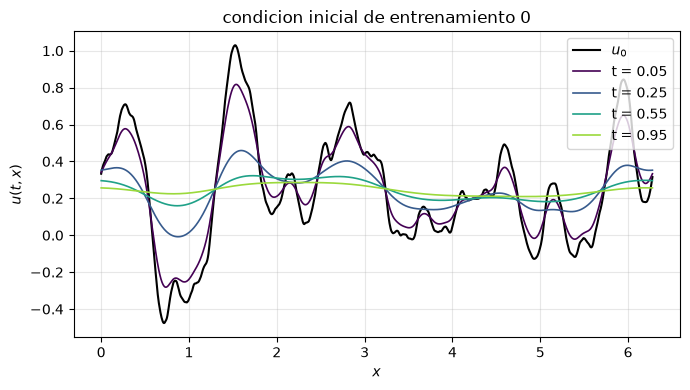

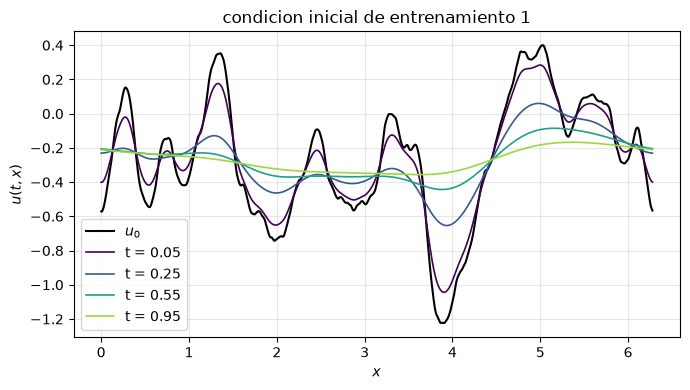

In [25]:
exp_1_0.initial_conditions()

## 2. Banda $(c,C)$, $\kappa$ y constantes $C_\alpha$

In [26]:
display(exp_1_0.estimate_constants())

estimate_symbol: 75,040 de 103,200 pares (k, t) con senal (tol=1e-10); 129 de 129 k de entrenamiento
  ventana usada: 129 k, |k|_inf <= 64, |k| in [0, 64]
(c, C) de los datos = (0.6364, 1.0999)   m = 1, ventana: 128 k, |k|_inf <= 64, |k| in [1, 64]
kappa teorico       = 2.2222   (omega = 1)
C_alpha estimadas   = 3 multiindices, |alpha| <= rho = 2


,C_alpha datos (x1.5),C_alpha oraculo (x1.5),k_usados
alpha,,,
"(0,)",1.499817,1.499817,129
"(1,)",1.500003,1.500000,128
"(2,)",4.242641,4.242641,127


## 3. Comprobaciones antes de entrenar

In [27]:
display(exp_1_0.checks())

tau = [1.]
capa 0: max |a(k) - a(-k)| = 0.000e+00   (|k| <= 512)


,valor,esperado
comprobacion,,
"paridad: max |a(k) - a(-k)|, |k| <= 512",0.000000e+00,0
"reduccion: max error relativo (4 u0 de prueba, t = [0.05, 0.5, 1.0])",1.996202e-07,~1e-06
"reduccion (fftn completa): max error relativo (4 u0 de prueba, t = [0.05, 0.5, 1.0])",1.999652e-07,~1e-06
semigrupo: max ||S(t+s)u0 - S(t)S(s)u0|| / ||u0|| (5 pares),1.310747e-07,~1e-06


## 4. Barrido de la MLP del simbolo

In [28]:
exp_1_0.sweep()

[  1/30] 2x32  drop[-] wd=0e+00 | rel_l2=0.0008 |  67.3s
[  2/30] 2x32  drop[-] wd=1e-04 | rel_l2=0.0008 |  69.1s
[  3/30] 2x64  drop[-] wd=0e+00 | rel_l2=0.0008 |  71.1s
[  4/30] 2x64  drop[-] wd=1e-04 | rel_l2=0.0008 |  67.0s
[  5/30] 2x128 drop[-] wd=0e+00 | rel_l2=0.0009 |  71.3s
[  6/30] 2x128 drop[-] wd=1e-04 | rel_l2=0.0009 |  70.5s
[  7/30] 3x32  drop[-] wd=0e+00 | rel_l2=0.0008 |  71.0s
[  8/30] 3x32  drop[-] wd=1e-04 | rel_l2=0.0008 |  17.4s
[  9/30] 3x32  drop[1] wd=0e+00 | rel_l2=0.0017 |  69.6s
[ 10/30] 3x32  drop[1] wd=1e-04 | rel_l2=0.0017 |  71.8s
[ 11/30] 3x64  drop[-] wd=0e+00 | rel_l2=0.0008 |  73.2s
[ 12/30] 3x64  drop[-] wd=1e-04 | rel_l2=0.0008 |  73.3s
[ 13/30] 3x64  drop[1] wd=0e+00 | rel_l2=0.0016 |  63.5s
[ 14/30] 3x64  drop[1] wd=1e-04 | rel_l2=0.0016 |  72.8s
[ 15/30] 3x128 drop[-] wd=0e+00 | rel_l2=0.0007 |  74.4s
[ 16/30] 3x128 drop[-] wd=1e-04 | rel_l2=0.0007 |  74.1s
[ 17/30] 3x128 drop[1] wd=0e+00 | rel_l2=0.0018 |  77.0s
[ 18/30] 3x128 drop[1] wd=1e-04

In [29]:
barrido, por_eje = exp_1_0.sweep_results()
display(barrido)
for tabla in por_eje:
    display(tabla)

,capas,ancho,dropout,weight_decay,val_rel_l2,val_total,val_par_max_ratio
0,4,128,OFF,0.0001,0.000045,0.000045,0.636347
1,4,128,OFF,0.0000,0.000046,0.000046,0.636334
2,4,64,OFF,0.0001,0.000681,0.000681,0.636304
3,4,64,OFF,0.0000,0.000693,0.000693,0.636305
4,3,128,OFF,0.0000,0.000728,0.000728,0.636324
5,3,128,OFF,0.0001,0.000733,0.000733,0.636323
6,3,32,OFF,0.0000,0.000833,0.000833,0.636341
7,3,64,OFF,0.0001,0.000836,0.000836,0.636367
8,3,64,OFF,0.0000,0.000836,0.000836,0.636357
9,2,64,OFF,0.0001,0.000838,0.000838,0.636323


,corridas,mejor_val_rel_l2,mejor_val_total,peor_ratio
dropout,,,,
OFF,18,0.000045,0.000045,0.636304
"ON p=0.2 capas[1,2]",6,0.002358,0.002358,0.634717
ON p=0.2 capas[1],6,0.001554,0.001554,0.634911


,corridas,mejor_val_rel_l2,mejor_val_total,peor_ratio
weight_decay,,,,
0.0000,15,0.000046,0.000046,0.634717
0.0001,15,0.000045,0.000045,0.635109


### Seleccion: la mejor aproximacion

In [30]:
display(exp_1_0.select())

kappa = theoretical_kappa() = 2.2222
arquitectura elegida    = 4 capas x 128 neuronas (MLP del simbolo)
dropout                 = OFF
weight decay            = 0.0001  (Linear ocultas interiores)
early stopping          = mejor epoca 275 de 300 epocas; se detuvo antes del final: False
tau                     = [1.]
C_alpha de train_operator = las de class_C.csv: True

metricas de validacion en la mejor epoca:
  total             = 4.5218e-05
  rel_l2            = 0.0000
  parabolicidad     = 0.0000e+00   (0 => ningun punto viola la cota)
  clase             = 0.0000e+00
  peor ratio        = 0.6363
  puntos con >1     = 0.00%


total                   0.000045
rel_l2                  0.000045
parabolicidad           0.000000
clase                   0.000000
peor ratio              0.636347
puntos con ratio > 1    0.000000
Name: validacion (mejor epoca), dtype: float64

## 5. Curvas de entrenamiento

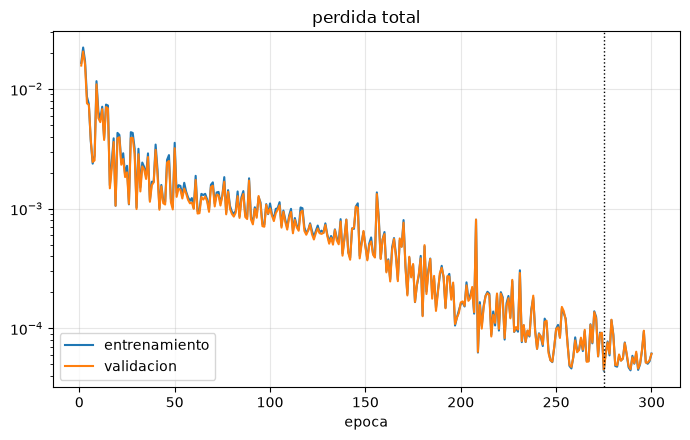

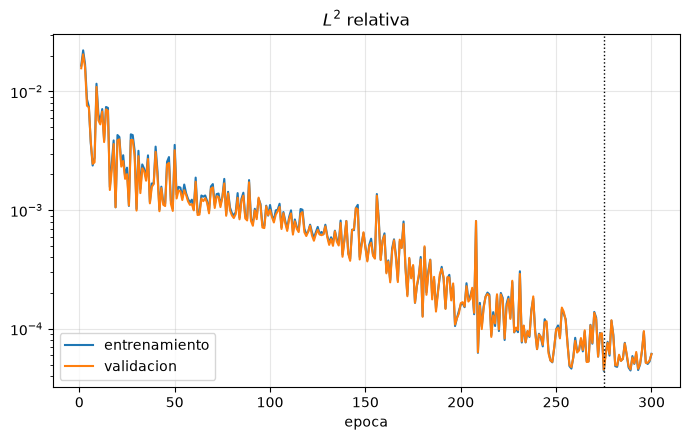

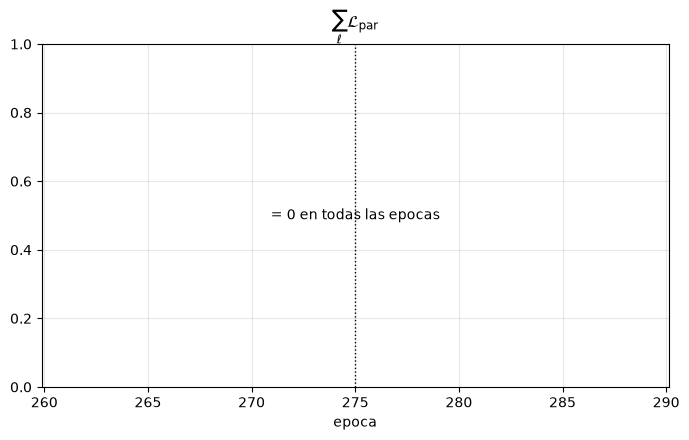

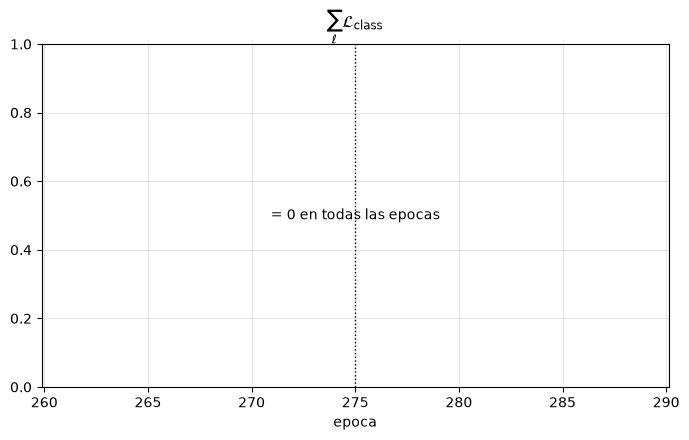

In [31]:
exp_1_0.curves()

## 6. Prueba

PRUEBA -- 20 condiciones iniciales nuevas x 20 tiempos
error relativo L2 (espacio fisico) = 3.7428e-05  (medio; max 1.1604e-04)
error relativo L2 (pares (k, t), |k| <= 64, simbolo efectivo) = 4.6812e-05


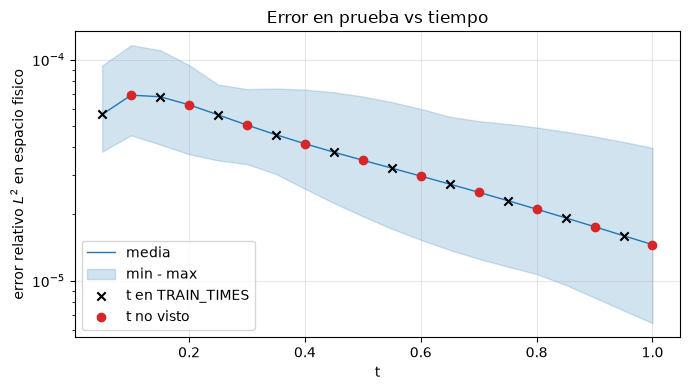

,media,max,en_entrenamiento
t,,,
0.05,0.000056,0.000094,True
0.10,0.000069,0.000116,False
0.15,0.000068,0.000110,True
0.20,0.000062,0.000094,False
0.25,0.000056,0.000077,True
0.30,0.000051,0.000073,False
0.35,0.000046,0.000074,True
0.40,0.000042,0.000073,False
0.45,0.000038,0.000071,True


In [32]:
display(exp_1_0.test())

**Campo.**

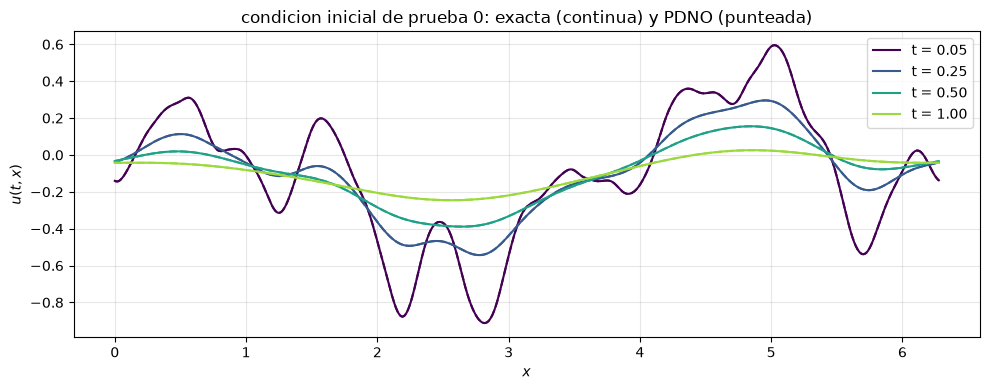

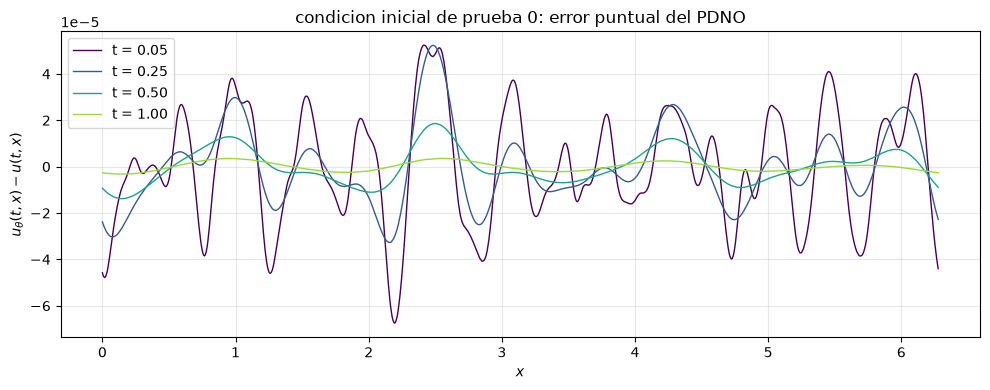

In [33]:
exp_1_0.field_figure()

## 7. Simbolo aprendido

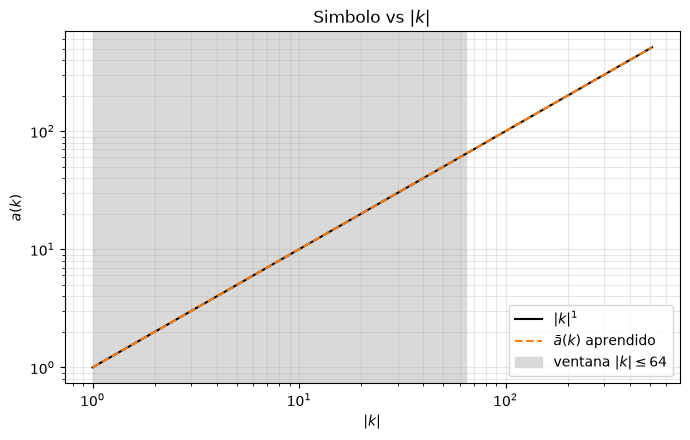

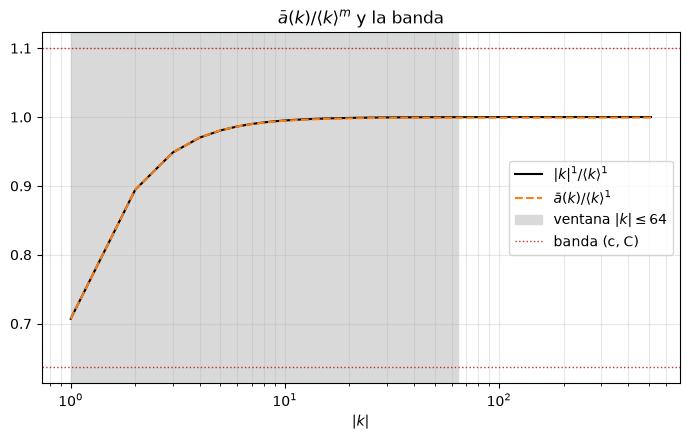

In [34]:
exp_1_0.symbol_figure()

**Error del simbolo.**

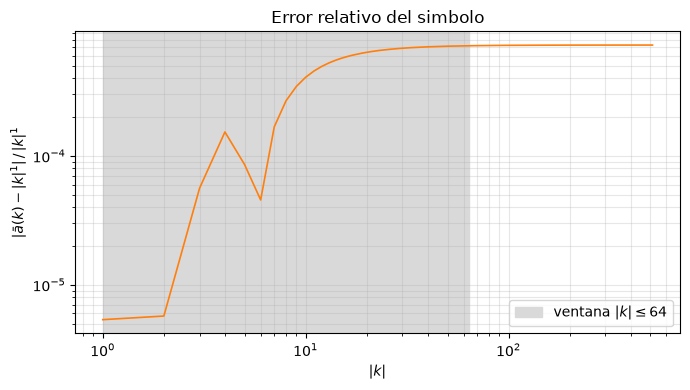

,dentro (|k| <= 64),fuera (|k| > 64)
n,129.000000,896.000000
mse,0.000684,0.052459
rmse,0.026154,0.229039
mae,0.021950,0.208937
max_error,0.045822,0.371033
rel_l2,0.000702,0.000724
error_relativo_medio,0.000592,0.000724
error_relativo_max,0.000716,0.000725


In [35]:
display(exp_1_0.symbol_error())

**Multiplicador.**

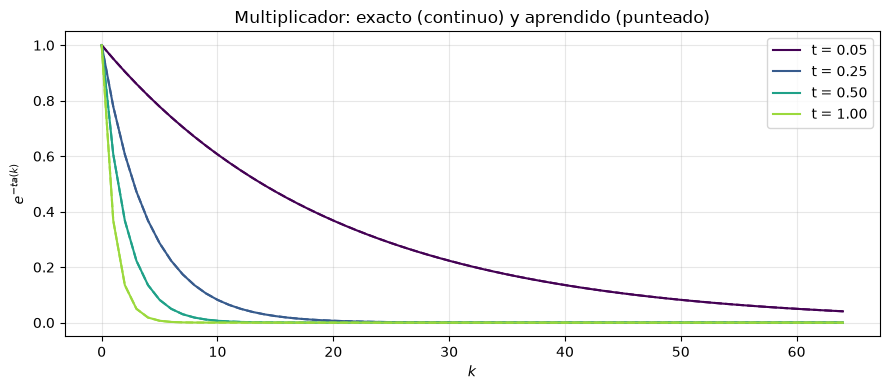

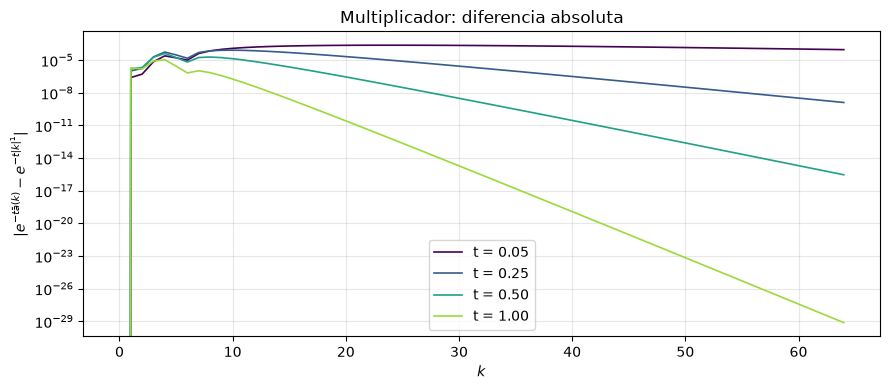

In [36]:
exp_1_0.multiplier()

## 8. Certificacion

In [37]:
display(exp_1_0.certification())

kappa usada = 2.2222


,simbolo,K,region,puntos,max_ratio,satisfecha
0,capa 0,64,dentro,80625,0.636377,True
1,capa 0,128,fuera,160625,0.636377,True
2,capa 0,192,fuera,240625,0.636377,True
3,efectivo,64,dentro,80625,0.636377,True
4,efectivo,128,fuera,160625,0.636377,True
5,efectivo,192,fuera,240625,0.636377,True


In [38]:
display(exp_1_0.symbol_class())

capa 0: consistentes 2 de 3 multiindices
efectivo: consistentes 2 de 3 multiindices
ventana explorada: |k| <= 128 (evidencia, no prueba sobre todo Z^n)
pendiente = nan significa Delta^alpha a = 0 en la ventana, asi que C_alpha = 0 basta


,simbolo,alpha,|alpha|,C_hat(4),C_hat(8),C_hat(12),C_hat(128),crecim.(12->128),pendiente,m-|alpha|,estable,consistente
0,capa 0,"(0,)",0,0.970291,0.992012,0.996053,0.999247,1.003207,1.000116,1.0,True,True
1,capa 0,"(1,)",1,1.000782,1.000782,1.000782,1.000782,1.000000,0.000010,0.0,True,True
2,capa 0,"(2,)",2,2.828442,2.828442,2.828442,2.828442,1.000000,-0.171865,-1.0,True,False
3,efectivo,"(0,)",0,0.970291,0.992012,0.996053,0.999247,1.003207,1.000116,1.0,True,True
4,efectivo,"(1,)",1,1.000782,1.000782,1.000782,1.000782,1.000000,0.000010,0.0,True,True
5,efectivo,"(2,)",2,2.828442,2.828442,2.828442,2.828442,1.000000,-0.171865,-1.0,True,False


## 9. Extrapolacion temporal

In [39]:
tabla_ext = exp_1_0.extrapolation()
if tabla_ext is not None:
    display(tabla_ext)

EXTRAPOLATION_TIMES = None: seccion omitida


## 10. Modelo guardado

In [40]:
exp_1_0.save_model()

modelo guardado en ../results/08_pdno_fraccionario_1d/alpha_1/modelo.pt


PosixPath('../results/08_pdno_fraccionario_1d/alpha_1/modelo.pt')

In [41]:
exp_1_0.check_saved_model()

dtype del modelo cargado = torch.float32
error de prueba (cargado) = 3.742844e-05  |  (entrenado) = 3.742844e-05
identicos: True


True

# $\alpha = 1.5$

$a(k)=|k|^{1.5}$, $m=1.5$, malla $1024$ puntos, $k_{\text{cap}}=64$. Tablas y figuras en `results/08_pdno_fraccionario_1d/alpha_1.5/`.

In [42]:
exp_1_5 = experimentos[1.5]

## 1. Datos

In [43]:
display(exp_1_5.load_data())

ENTRENAMIENTO
100 condiciones iniciales x 10 tiempos, resolucion 1024: 1290 pares (k, t) con |k|_inf <= 64 -> 129,000 muestras
  ventana de k: 129 k, |k|_inf <= 64, |k| in [0, 64]
PRUEBA
20 condiciones iniciales x 20 tiempos, resolucion 1024: 2580 pares (k, t) con |k|_inf <= 64 -> 51,600 muestras
  ventana de k: 129 k, |k|_inf <= 64, |k| in [0, 64]
CAMPOS (condicion inicial x tiempo)
  train        : 80 u0 x 10 tiempos = 800 pares, malla (1024,)
  val          : 20 u0 x 10 tiempos = 200 pares, malla (1024,)
  test         : 20 u0 x 20 tiempos = 400 pares, malla (1024,)

k_max = k_cap = 64
entrenamiento :  80 condiciones iniciales x 10 tiempos =  800 pares
validacion    :  20 condiciones iniciales x 10 tiempos =  200 pares
prueba        :  20 condiciones iniciales x 20 tiempos =  400 pares
entrenamiento y validacion disjuntos: True
prueba: min ||u0_prueba - u0_vista|| / ||u0_prueba|| = 1.007  (> 0: disjunta)
filas espectrales para la banda y las C_alpha: 103,200 (solo las 80 u0 de entre

,condiciones_iniciales,tiempos,pares,t_min,t_max
conjunto,,,,,
entrenamiento,80,10,800,0.05,0.95
validacion,20,10,200,0.05,0.95
prueba,20,20,400,0.05,1.00


**Condiciones iniciales y evolucion.**

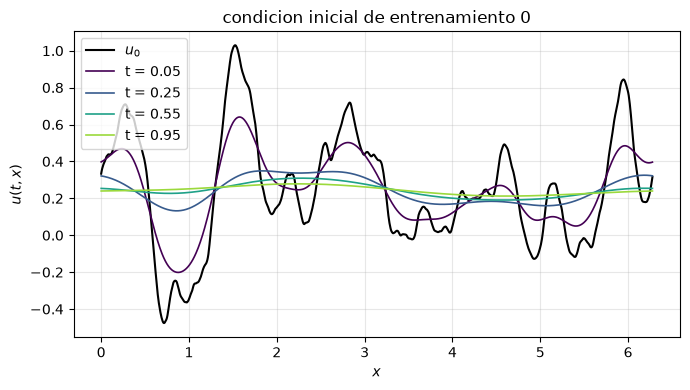

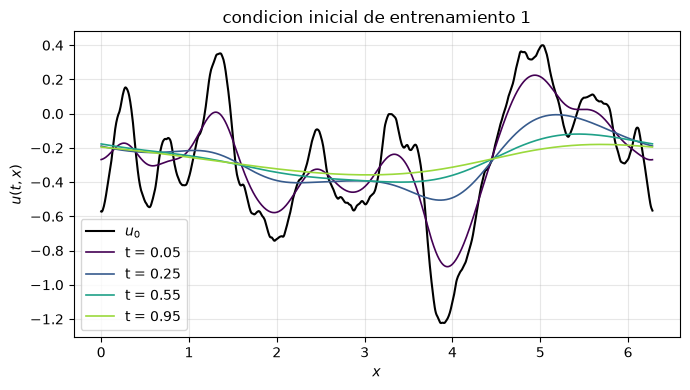

In [44]:
exp_1_5.initial_conditions()

## 2. Banda $(c,C)$, $\kappa$ y constantes $C_\alpha$

In [45]:
display(exp_1_5.estimate_constants())

estimate_symbol: 30,240 de 103,200 pares (k, t) con senal (tol=1e-10); 119 de 129 k de entrenamiento
  ventana usada: 119 k, |k|_inf <= 59, |k| in [0, 59]
(c, C) de los datos = (0.5351, 1.0998)   m = 1.5, ventana: 118 k, |k|_inf <= 59, |k| in [1, 59]
kappa teorico       = 2.6427   (omega = 1)
C_alpha estimadas   = 3 multiindices, |alpha| <= rho = 2


,C_alpha datos (x1.5),C_alpha oraculo (x1.5),k_usados
alpha,,,
"(0,)",1.499677,1.499725,119
"(1,)",2.375090,2.375090,118
"(2,)",3.567621,3.567621,117


## 3. Comprobaciones antes de entrenar

In [46]:
display(exp_1_5.checks())

tau = [1.]
capa 0: max |a(k) - a(-k)| = 0.000e+00   (|k| <= 512)


,valor,esperado
comprobacion,,
"paridad: max |a(k) - a(-k)|, |k| <= 512",0.000000e+00,0
"reduccion: max error relativo (4 u0 de prueba, t = [0.05, 0.5, 1.0])",2.310717e-07,~1e-06
"reduccion (fftn completa): max error relativo (4 u0 de prueba, t = [0.05, 0.5, 1.0])",2.097351e-07,~1e-06
semigrupo: max ||S(t+s)u0 - S(t)S(s)u0|| / ||u0|| (5 pares),1.640821e-07,~1e-06


## 4. Barrido de la MLP del simbolo

In [47]:
exp_1_5.sweep()

[  1/30] 2x32  drop[-] wd=0e+00 | rel_l2=0.0009 |  30.6s
[  2/30] 2x32  drop[-] wd=1e-04 | rel_l2=0.0009 |  66.8s
[  3/30] 2x64  drop[-] wd=0e+00 | rel_l2=0.0010 |  38.5s
[  4/30] 2x64  drop[-] wd=1e-04 | rel_l2=0.0010 |  67.5s
[  5/30] 2x128 drop[-] wd=0e+00 | rel_l2=0.0010 |  69.3s
[  6/30] 2x128 drop[-] wd=1e-04 | rel_l2=0.0010 |  68.9s
[  7/30] 3x32  drop[-] wd=0e+00 | rel_l2=0.0010 |  73.0s
[  8/30] 3x32  drop[-] wd=1e-04 | rel_l2=0.0010 |  71.0s
[  9/30] 3x32  drop[1] wd=0e+00 | rel_l2=0.0021 |  75.6s
[ 10/30] 3x32  drop[1] wd=1e-04 | rel_l2=0.0021 |  76.7s
[ 11/30] 3x64  drop[-] wd=0e+00 | rel_l2=0.0011 |  19.2s
[ 12/30] 3x64  drop[-] wd=1e-04 | rel_l2=0.0010 |  72.2s
[ 13/30] 3x64  drop[1] wd=0e+00 | rel_l2=0.0019 |  76.6s
[ 14/30] 3x64  drop[1] wd=1e-04 | rel_l2=0.0020 |  77.3s
[ 15/30] 3x128 drop[-] wd=0e+00 | rel_l2=0.0004 |  76.2s
[ 16/30] 3x128 drop[-] wd=1e-04 | rel_l2=0.0005 |  73.5s
[ 17/30] 3x128 drop[1] wd=0e+00 | rel_l2=0.0021 |  76.2s
[ 18/30] 3x128 drop[1] wd=1e-04

In [48]:
barrido, por_eje = exp_1_5.sweep_results()
display(barrido)
for tabla in por_eje:
    display(tabla)

,capas,ancho,dropout,weight_decay,val_rel_l2,val_total,val_par_max_ratio
0,4,128,OFF,0.0000,0.000019,0.000019,0.655343
1,4,128,OFF,0.0001,0.000024,0.000024,0.655341
2,4,32,OFF,0.0000,0.000112,0.000112,0.655340
3,4,32,OFF,0.0001,0.000122,0.000122,0.655340
4,3,128,OFF,0.0000,0.000437,0.000437,0.655324
5,3,128,OFF,0.0001,0.000529,0.000529,0.655335
6,2,32,OFF,0.0001,0.000911,0.000911,0.655337
7,2,32,OFF,0.0000,0.000912,0.000912,0.655334
8,3,32,OFF,0.0001,0.000962,0.000962,0.655337
9,3,32,OFF,0.0000,0.000962,0.000962,0.655337


,corridas,mejor_val_rel_l2,mejor_val_total,peor_ratio
dropout,,,,
OFF,18,0.000019,0.000019,0.655316
"ON p=0.2 capas[1,2]",6,0.002860,0.002860,0.645427
ON p=0.2 capas[1],6,0.001930,0.001930,0.654198


,corridas,mejor_val_rel_l2,mejor_val_total,peor_ratio
weight_decay,,,,
0.0000,15,0.000019,0.000019,0.645427
0.0001,15,0.000024,0.000024,0.645943


### Seleccion: la mejor aproximacion

In [49]:
display(exp_1_5.select())

kappa = theoretical_kappa() = 2.6427
arquitectura elegida    = 4 capas x 128 neuronas (MLP del simbolo)
dropout                 = OFF
weight decay            = 0  (Linear ocultas interiores)
early stopping          = mejor epoca 281 de 300 epocas; se detuvo antes del final: False
tau                     = [1.]
C_alpha de train_operator = las de class_C.csv: True

metricas de validacion en la mejor epoca:
  total             = 1.8659e-05
  rel_l2            = 0.0000
  parabolicidad     = 0.0000e+00   (0 => ningun punto viola la cota)
  clase             = 0.0000e+00
  peor ratio        = 0.6553
  puntos con >1     = 0.00%


total                   0.000019
rel_l2                  0.000019
parabolicidad           0.000000
clase                   0.000000
peor ratio              0.655343
puntos con ratio > 1    0.000000
Name: validacion (mejor epoca), dtype: float64

## 5. Curvas de entrenamiento

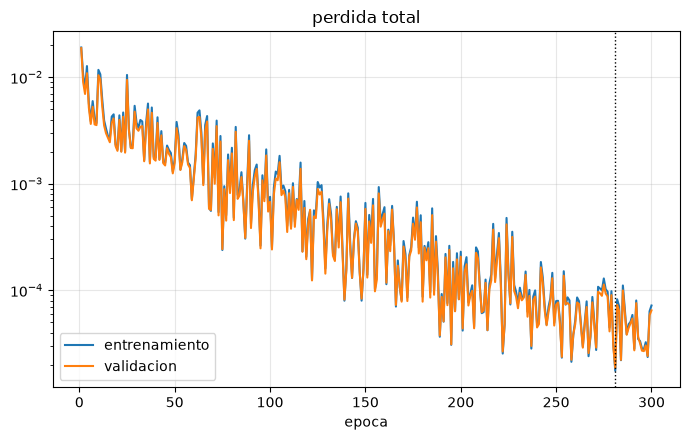

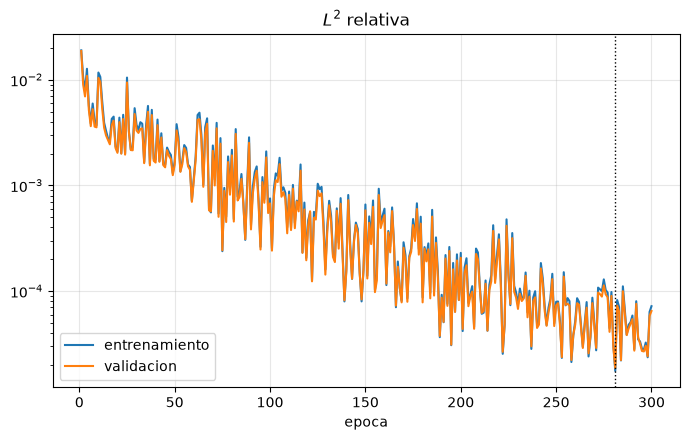

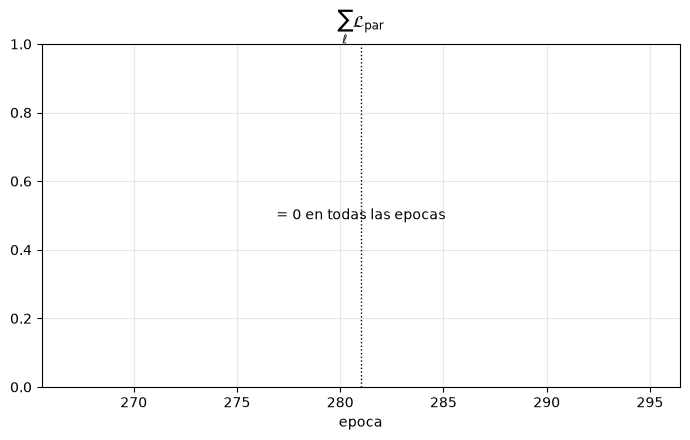

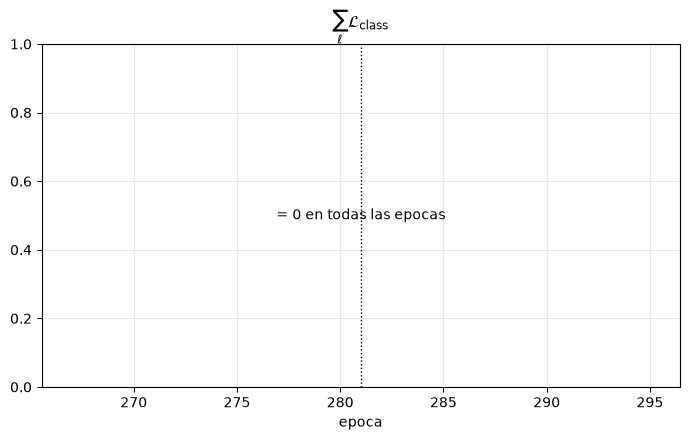

In [50]:
exp_1_5.curves()

## 6. Prueba

PRUEBA -- 20 condiciones iniciales nuevas x 20 tiempos
error relativo L2 (espacio fisico) = 1.4565e-05  (medio; max 1.4868e-04)
error relativo L2 (pares (k, t), |k| <= 64, simbolo efectivo) = 3.1993e-05


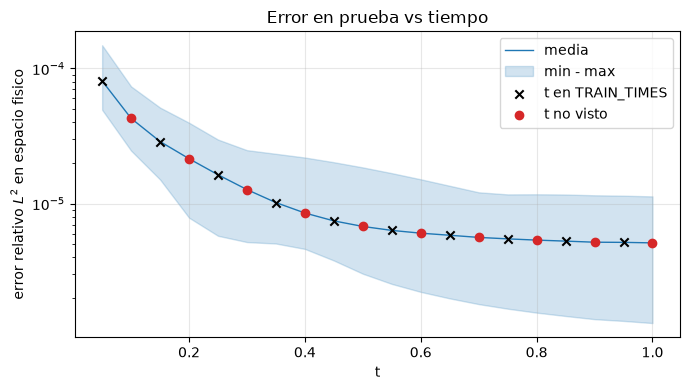

,media,max,en_entrenamiento
t,,,
0.05,0.000081,0.000149,True
0.10,0.000043,0.000074,False
0.15,0.000029,0.000051,True
0.20,0.000021,0.000040,False
0.25,0.000016,0.000030,True
0.30,0.000013,0.000025,False
0.35,0.000010,0.000023,True
0.40,0.000009,0.000022,False
0.45,0.000007,0.000020,True


In [51]:
display(exp_1_5.test())

**Campo.**

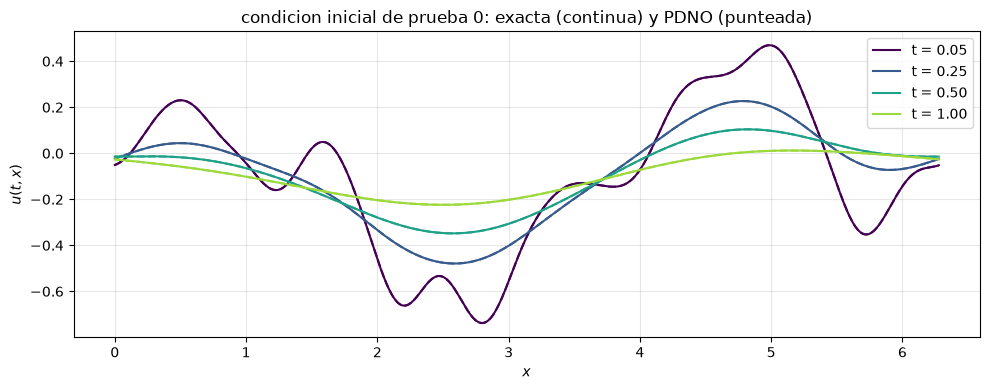

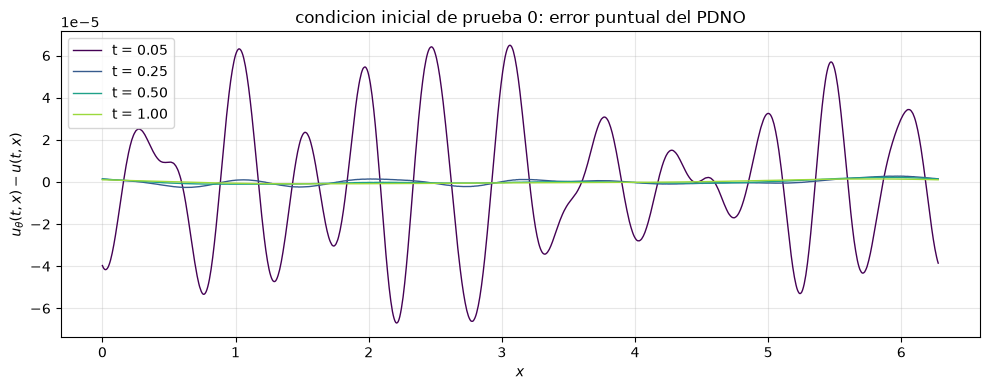

In [52]:
exp_1_5.field_figure()

## 7. Simbolo aprendido

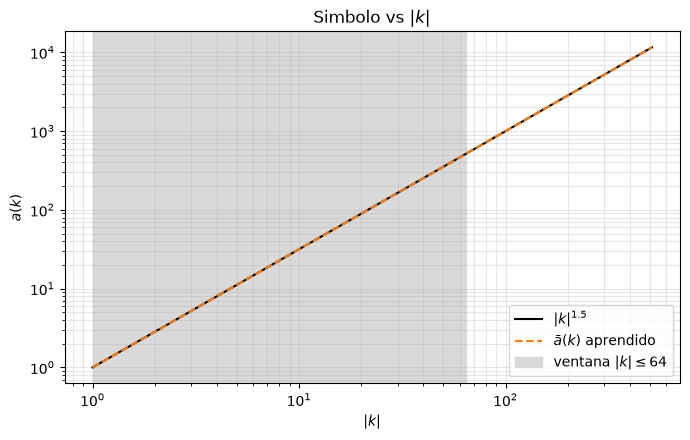

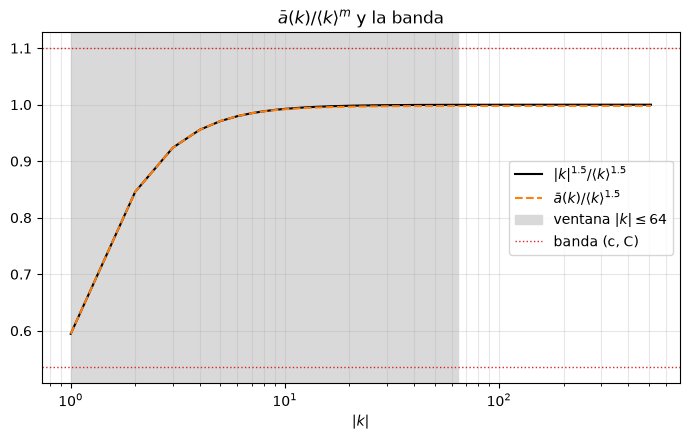

In [53]:
exp_1_5.symbol_figure()

**Error del simbolo.**

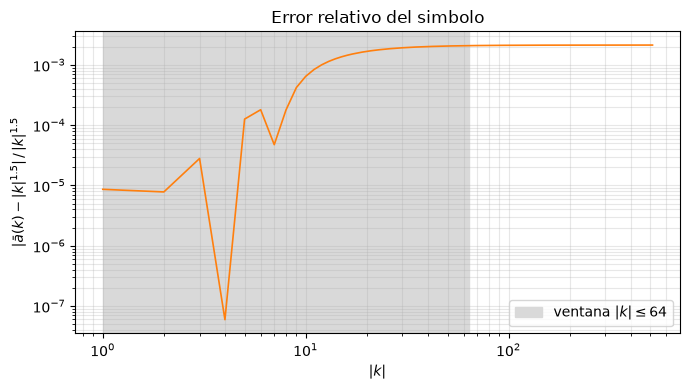

,dentro (|k| <= 64),fuera (|k| > 64)
n,129.000000,896.000000
mse,0.280251,174.772794
rmse,0.529387,13.220166
mae,0.410155,11.244745
max_error,1.067596,24.695511
rel_l2,0.002044,0.002131
error_relativo_medio,0.001603,0.002127
error_relativo_max,0.002085,0.002132


In [54]:
display(exp_1_5.symbol_error())

**Multiplicador.**

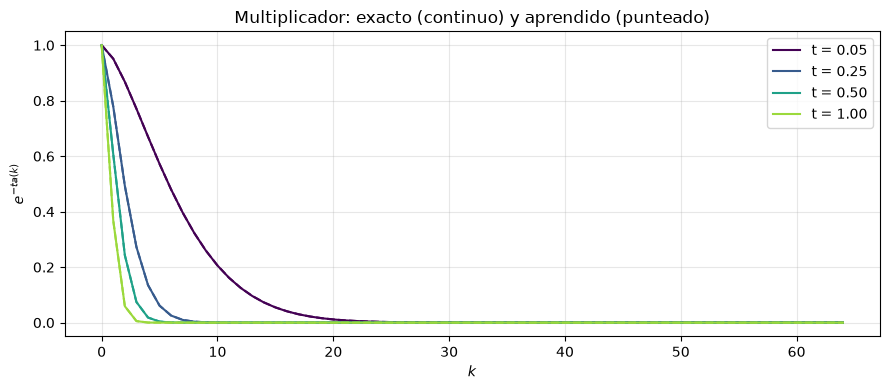

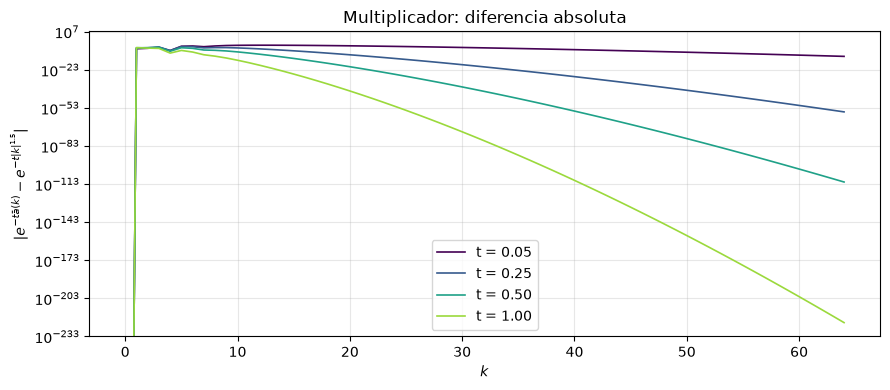

In [55]:
exp_1_5.multiplier()

## 8. Certificacion

In [56]:
display(exp_1_5.certification())

kappa usada = 2.6427


,simbolo,K,region,puntos,max_ratio,satisfecha
0,capa 0,64,dentro,80625,0.654645,True
1,capa 0,128,fuera,160625,0.654645,True
2,capa 0,192,fuera,240625,0.654645,True
3,efectivo,64,dentro,80625,0.654645,True
4,efectivo,128,fuera,160625,0.654645,True
5,efectivo,192,fuera,240625,0.654645,True


In [57]:
display(exp_1_5.symbol_class())

capa 0: consistentes 3 de 3 multiindices
efectivo: consistentes 3 de 3 multiindices
ventana explorada: |k| <= 128 (evidencia, no prueba sobre todo Z^n)
pendiente = nan significa Delta^alpha a = 0 en la ventana, asi que C_alpha = 0 basta


,simbolo,alpha,|alpha|,C_hat(4),C_hat(8),C_hat(12),C_hat(128),crecim.(12->128),pendiente,m-|alpha|,estable,consistente
0,capa 0,"(0,)",0,0.955550,0.988262,0.993824,0.997834,1.004035,1.500139,1.5,True,True
1,capa 0,"(1,)",1,1.583476,1.583476,1.583476,1.583476,1.000000,0.497340,0.5,True,True
2,capa 0,"(2,)",2,2.378394,2.378394,2.378394,2.378394,1.000000,-0.505941,-0.5,True,True
3,efectivo,"(0,)",0,0.955550,0.988262,0.993824,0.997834,1.004035,1.500139,1.5,True,True
4,efectivo,"(1,)",1,1.583476,1.583476,1.583476,1.583476,1.000000,0.497340,0.5,True,True
5,efectivo,"(2,)",2,2.378394,2.378394,2.378394,2.378394,1.000000,-0.505941,-0.5,True,True


## 9. Extrapolacion temporal

In [58]:
tabla_ext = exp_1_5.extrapolation()
if tabla_ext is not None:
    display(tabla_ext)

EXTRAPOLATION_TIMES = None: seccion omitida


## 10. Modelo guardado

In [59]:
exp_1_5.save_model()

modelo guardado en ../results/08_pdno_fraccionario_1d/alpha_1.5/modelo.pt


PosixPath('../results/08_pdno_fraccionario_1d/alpha_1.5/modelo.pt')

In [60]:
exp_1_5.check_saved_model()

dtype del modelo cargado = torch.float32
error de prueba (cargado) = 1.456459e-05  |  (entrenado) = 1.456459e-05
identicos: True


True

# Resumen

Una fila por $\alpha$, con las columnas de `results/04_fraccionario_1d/resumen.csv`: ventana de $k$, $c$, $C$, $\kappa$, configuracion elegida, $L^2$ relativa de validacion, error en prueba (pares $(k,t)$ con el simbolo efectivo y espacio fisico), error relativo medio del simbolo dentro de la ventana, peor ratio de la certificacion y multiindices consistentes del simbolo efectivo. Ademas, las del PDNO: error maximo en prueba en espacio fisico, error relativo medio del simbolo fuera de la ventana y las comprobaciones de paridad y semigrupo. Se guarda en `resumen.csv`.

In [61]:
display(pdno_summary_table(experimentos, RESULTS))

,alpha,ventana_k,c,C,kappa,configuracion,val_rel_l2,test_rel_l2,test_rel_l2_fisico,error_simbolo_medio,peor_ratio,multiindices_consistentes,test_rel_l2_fisico_max,error_simbolo_medio_fuera,paridad,semigrupo
0,0.5,"129 k, |k|_inf <= 64, |k| in [0, 64]",0.756807,1.099933,2.000000,"4x128, dropout OFF, wd=0",0.000015,0.000012,0.000014,0.000078,0.594582,3/3,0.000027,0.000096,0.0,2.449132e-07
1,1.0,"129 k, |k|_inf <= 64, |k| in [0, 64]",0.636396,1.099866,2.222222,"4x128, dropout OFF, wd=0.0001",0.000045,0.000047,0.000037,0.000592,0.636377,2/3,0.000116,0.000724,0.0,1.310747e-07
2,1.5,"129 k, |k|_inf <= 64, |k| in [0, 64]",0.535143,1.099763,2.642682,"4x128, dropout OFF, wd=0",0.000019,0.000032,0.000015,0.001603,0.654645,3/3,0.000149,0.002127,0.0,1.640821e-07


Error en prueba (pares $(k,t)$ y espacio fisico) y peor ratio de la certificacion contra $\alpha$, leidos de `resumen.csv`, en dos imagenes: `resumen_error_prueba.png` y `resumen_certificacion.png` (la linea discontinua es la cota de la Def. 2.3, ratio $=1$).

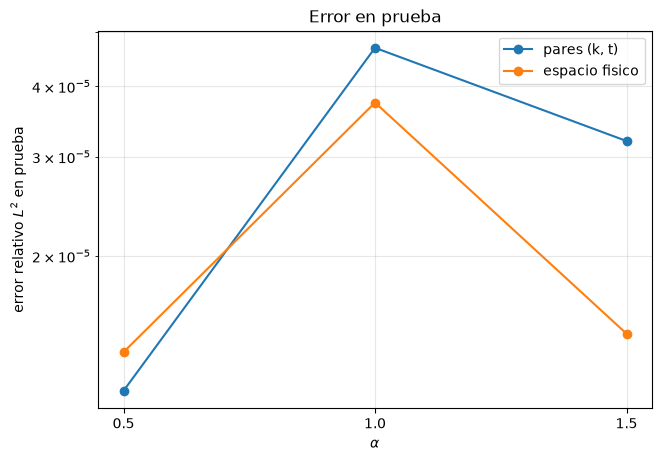

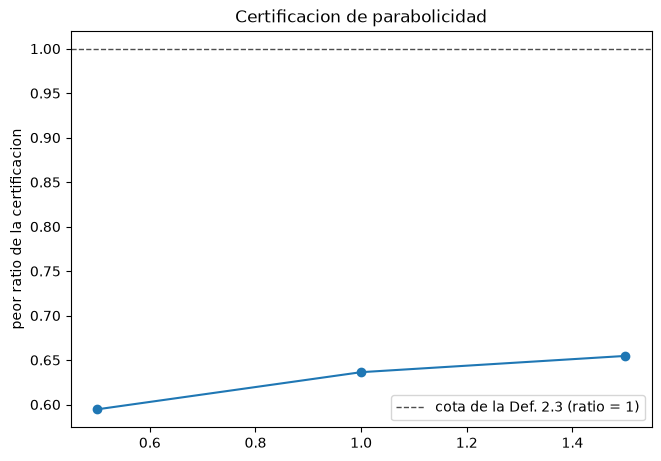

In [62]:
pdno_summary_figures(RESULTS / "resumen.csv", RESULTS)